<a href="https://colab.research.google.com/github/jeevaprakash-S/24ADI006_24BAD048/blob/main/Experiment_8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **PART A: DATASET PREPARATION AND PREPROCESSING**

Jeevaprakash S - 24BAD048
11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

Dataset Information
Training images: (60000, 28, 28)
Testing images: (10000, 28, 28)
Image dimensions: (28, 28)
Number of training samples: 60000
Number of testing samples: 10000


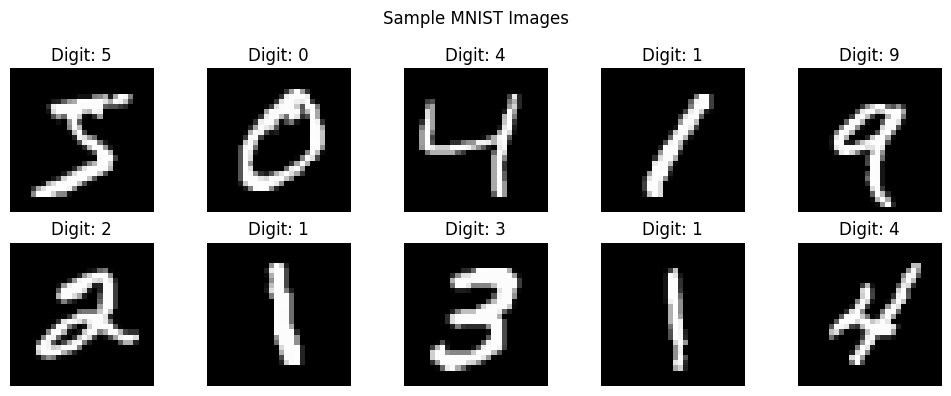


After Preprocessing
Training input shape: (60000, 784)
Training target shape: (60000, 784)
Testing input shape: (10000, 784)
Testing target shape: (10000, 784)
Minimum pixel value: 0.0
Maximum pixel value: 1.0


In [1]:
print("Jeevaprakash S - 24BAD048")

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

print("\nDataset Information")
print("Training images:", x_train.shape)
print("Testing images:", x_test.shape)
print("Image dimensions:", x_train.shape[1:])
print("Number of training samples:", len(x_train))
print("Number of testing samples:", len(x_test))
plt.figure(figsize=(10, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap='gray')
    plt.title(f"Digit: {y_train[i]}")
    plt.axis('off')

plt.suptitle("Sample MNIST Images")
plt.tight_layout()
plt.show()

x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

x_train = x_train.reshape(-1, 784)
x_test = x_test.reshape(-1, 784)
x_train_input = x_train
x_train_target = x_train
x_test_input = x_test
x_test_target = x_test

print("\nAfter Preprocessing")
print("Training input shape:", x_train_input.shape)
print("Training target shape:", x_train_target.shape)
print("Testing input shape:", x_test_input.shape)
print("Testing target shape:", x_test_target.shape)
print("Minimum pixel value:", np.min(x_train))
print("Maximum pixel value:", np.max(x_train))


# **PART B: IMPLEMENTING ENCODER AND DECODER**

In [2]:
print("Jeevaprakash S - 24BAD048")

from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.models import Model

# Define input layer
input_layer = Input(shape=(784,), name="Input_Layer")

# Build Encoder
encoded = Dense(128, activation='relu')(input_layer)
latent = Dense(32, activation='relu', name="Latent_Layer")(encoded)

# Create Encoder Model
encoder = Model(input_layer, latent, name="Encoder")

# Build Decoder
decoder_input = Input(shape=(32,), name="Decoder_Input")

decoded = Dense(128, activation='relu')(decoder_input)
output_layer = Dense(784, activation='sigmoid')(decoded)

# Create Decoder Model
decoder = Model(decoder_input, output_layer, name="Decoder")

# Combine Encoder and Decoder
autoencoder_output = decoder(encoder(input_layer))

autoencoder = Model(
    input_layer,
    autoencoder_output,
    name="MNIST_Autoencoder"
)

# Display model summaries
print("\nENCODER SUMMARY")
encoder.summary()

print("\nDECODER SUMMARY")
decoder.summary()

print("\nAUTOENCODER SUMMARY")
autoencoder.summary()


Jeevaprakash S - 24BAD048

ENCODER SUMMARY


Model: "Encoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Input_Layer (InputLayer)        │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Latent_Layer (Dense)            │ (None, 32)             │         4,128 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 104,608 (408.62 KB)

 Trainable params: 104,608 (408.62 KB)

 Non-trainable params: 0 (0.00 B)

... (8 outputs left out)

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Input_Layer (InputLayer)        │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Encoder (Functional)            │ (None, 32)             │       104,608 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Decoder (Functional)            │ (None, 784)            │       105,360 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 209,968 (820.19 KB)

 Trainable params: 209,968 (820.19 KB)

 Non-trainable params: 0 (0.00 B)

# **PART C: COMPILING AND TRAINING AUTOENCODER**

Jeevaprakash S - 24BAD048
Epoch 1/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 5s 14ms/step - loss: 0.0597 - val_loss: 0.0317
Epoch 2/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - loss: 0.0257 - val_loss: 0.0212
Epoch 3/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 19ms/step - loss: 0.0195 - val_loss: 0.0171
Epoch 4/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 15ms/step - loss: 0.0166 - val_loss: 0.0151
Epoch 5/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - loss: 0.0149 - val_loss: 0.0138
Epoch 6/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 6s 17ms/step - loss: 0.0137 - val_loss: 0.0128
Epoch 7/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - loss: 0.0129 - val_loss: 0.0122
Epoch 8/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - loss: 0.0123 - val_loss: 0.0118
Epoch 9/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - loss: 0.0120 - val_loss: 0.0115
Epoch 10/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 5s 21ms/step - loss: 0.0117 - val_loss: 0.0112

Training Loss: 0.011665821075439453
Validation Loss: 0.011218267492949963


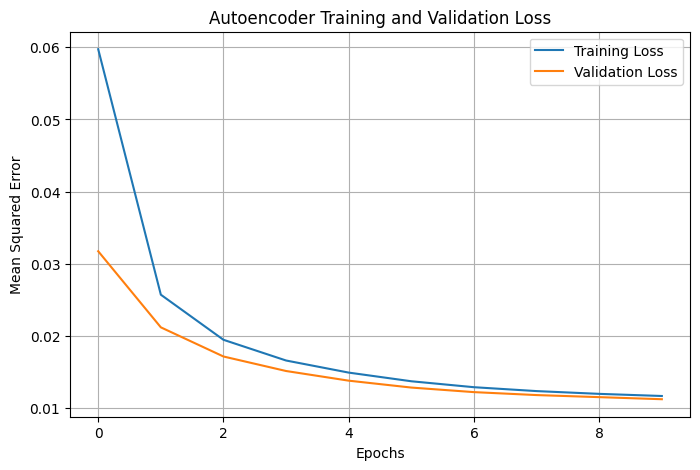

In [3]:
print("Jeevaprakash S - 24BAD048")
# Compile the autoencoder
autoencoder.compile(
    optimizer='adam',
    loss='mean_squared_error'
)

# Train the autoencoder
history = autoencoder.fit(
    x_train_input,
    x_train_target,
    epochs=10,
    batch_size=256,
    shuffle=True,
    validation_data=(x_test_input, x_test_target)
)

# Display training and validation loss
print("\nTraining Loss:", history.history['loss'][-1])
print("Validation Loss:", history.history['val_loss'][-1])

# Plot training and validation loss
plt.figure(figsize=(8, 5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title("Autoencoder Training and Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Mean Squared Error")
plt.legend()
plt.grid(True)

plt.show()


# **PART D: DIMENSIONALITY REDUCTION AND RECONSTRUCTION**

Jeevaprakash S - 24BAD048
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Original Input Dimension: 784
Latent Dimension: 32
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Reconstructed Images Shape: (10000, 784)


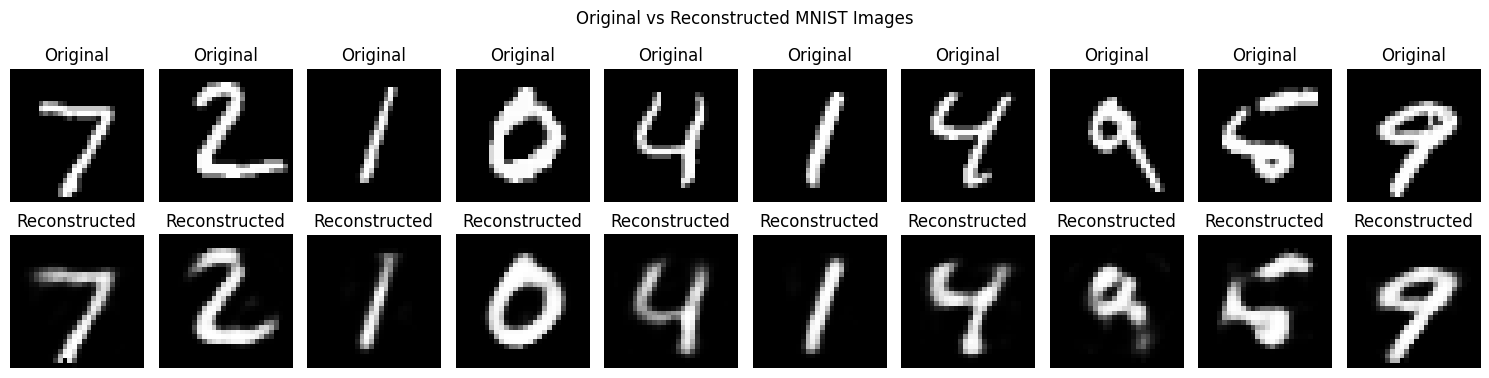


Autoencoder model saved successfully!
Reconstructed images saved successfully!


In [4]:
print("Jeevaprakash S - 24BAD048")

# Convert test images into latent representations
encoded_images = encoder.predict(x_test_input)

# Display dimensions
print("Original Input Dimension:", x_test_input.shape[1])
print("Latent Dimension:", encoded_images.shape[1])

# Reconstruct images using decoder
decoded_images = decoder.predict(encoded_images)

print("Reconstructed Images Shape:", decoded_images.shape)

# Display original and reconstructed images
n = 10

plt.figure(figsize=(15, 4))

for i in range(n):

    # Original images
    ax = plt.subplot(2, n, i + 1)
    plt.imshow(x_test_input[i].reshape(28, 28), cmap='gray')
    plt.title("Original")
    plt.axis('off')

    # Reconstructed images
    ax = plt.subplot(2, n, i + 1 + n)
    plt.imshow(decoded_images[i].reshape(28, 28), cmap='gray')
    plt.title("Reconstructed")
    plt.axis('off')

plt.suptitle("Original vs Reconstructed MNIST Images")
plt.tight_layout()
plt.show()

# Save trained autoencoder
autoencoder.save("Jeevaprakash_24BAD048_Autoencoder.keras")

# Save reconstructed images
np.save("reconstructed_images.npy", decoded_images)

print("\nAutoencoder model saved successfully!")
print("Reconstructed images saved successfully!")
